# นับดอกไม้ + บอกชนิด จากหลายรูป (v4 = v2 + กันการ์ตูน/เกม + ดอกไม้ปลอม)

> **เวอร์ชัน v4.7** (ไฟล์สำรอง) — กล่องแจกันไม่แทนกล่อง YOLO  
> ไฟล์ล่าสุดคือ `../flower_counter_v4.ipynb`

```
เพิ่มรูป (หลายรูป/หลายรอบ) → กด "ตรวจทั้งหมด"
   แต่ละรูป: ด่าน 1 เป็นดอกไม้ไหม? (CLIP) → ไม่ใช่ = แจ้งเตือน
             ด่าน 2 เป็นภาพถ่ายจริงไหม? การ์ตูน/เกม/ภาพวาด = แจ้งเตือน, ดอกไม้ปลอม (พลาสติก/ผ้า) = ผ่าน
             ใช่ → detect ทีละดอก (OWLv2 หรือ YOLO) → crop → ตัดของที่ไม่ใช่ดอกไม้
                 → BioCLIP 2 ทายชนิดทีละดอก (ชื่อวิทยาศาสตร์ + รูปตัวอย่าง + บริบททั้งรูป)
   สุดท้าย: สรุปรวมทุกรูป (ดอกทั้งหมดกี่ดอก ชนิดละกี่ดอก อยู่ในกี่รูป)
```

**สิ่งที่เปลี่ยนจากเวอร์ชันเดิม**
1. prompt ของ BioCLIP ใช้ **ชื่อวิทยาศาสตร์** (เช่น *Tulipa gesneriana*) เพราะ BioCLIP เทรนด้วยชื่อแบบนี้
2. อัปเกรดเป็น **BioCLIP 2** (ทายชนิดแม่นกว่ารุ่นแรกมาก)
3. ผสม **บริบทของทั้งรูป** เข้ากับแต่ละดอก (`CONTEXT_WEIGHT`)
4. ใส่ **รูปตัวอย่าง** ของแต่ละชนิดได้ (`refs/<ชนิด>/*.jpg`) แม่นที่สุดในบรรดาทุกข้อ
5. Detector เริ่มต้นเป็น **OWLv2** (zero-shot หาดอกไม้ได้ทุกแบบ) หรือ YOLO ที่ train แบบ `single_cls`
6. ตัดกล่องที่ครอบทั้งช่อออก ไม่ให้นับเป็น 1 ดอก
7. **(v4)** ปฏิเสธดอกไม้การ์ตูน/ในเกม และดอกไม้ปลอมให้ใช้ CLIP ViT-L-14 ช่วยบอกชนิด (โหลดเฉพาะตอนเจอดอกไม้ปลอม)
8. **(v4.1) นับทีละดอกแม่นขึ้น** ทดสอบกับ 15 รูป ผิดรวมจาก ~65 ดอก เหลือ ~10 ดอก
   - OWLv2 ค้นด้วย `"flower"` + ชื่อดอกไม้ทุกชนิดใน `flowers` (เดิม `"a photo of a flower"` ได้กล่องครอบทั้งรูป แล้วกล่องดอกจริงถูกตัดทิ้ง)
   - เกณฑ์คะแนนปรับตามรูป (`DET_REL` × คะแนนสูงสุดในรูป) เพราะคะแนน OWLv2 ต่างกันมากในแต่ละรูป
   - กล่องซ้อนกัน (กลีบในดอก / ดอก+ก้าน) เหลือกล่องเดียว และเลือกกล่องที่เป็นตัวดอก
   - ภาพถ่ายจริงพื้นดำไม่ถูกปัดเป็นการ์ตูนแล้ว และดอกจริงไม่ถูกเรียกว่าดอกไม้ปลอม (`DRAWN_THR`, `ARTIFICIAL_THR` = 0.8)
9. **(v4.2) YOLO นับแม่นขึ้น**
   - `YOLO_CONF` 0.25 → 0.15 และเปิด TTA (`YOLO_TTA`) หาดอกที่เคยหลุด (ดอกด้านหลัง/ชนิดที่ไม่มีใน dataset)
   - ตัดกล่องเล็กผิดปกติ (`MIN_REL_AREA` × ขนาดกลางของกล่องในรูป) = เศษกลีบ ไม่ใช่ดอก
   - ด่านกรอง crop รู้จักริบบิ้น/กระดาษห่อ ไม่นับเป็นดอก
10. **(v4.3) รันใน VS Code ได้** อ่านรูปจากโฟลเดอร์ (`IMAGE_DIR`) แทนการอัปโหลด, รูปตัวอย่างวางใน `refs/<ชนิด>/`
11. **(v4.4) เลือก detector ได้ 3 แบบ** `"yolo"`, `"owl2"`, `"yolo+owl2"` (YOLO เป็นหลัก + เติมดอกที่ OWLv2 เจอแต่ YOLO ไม่เจอ)
   - แก้บั๊ก: ดอกริมรูปที่มีเศษกลีบซ้อนอยู่ถูกมองเป็นกล่องทั้งช่อแล้วถูกตัดทิ้ง (ตัดเศษกลีบก่อนแล้ว)
12. **(v4.5) ช่อดอกไม้ผสมหลายชนิด + เซลล์สรุปไม่ค้าง**
   - ใช้บริบททั้งรูปเฉพาะรูปที่เป็นดอกชนิดเดียวชัดๆ (`CONTEXT_MIN`) ช่อผสมเคยถูกดึงไปเป็นชนิดเดียวกันหมด/กลายเป็น unknown
   - `CROP_FLOWER_THR` 0.25 → 0.5 ตัดกล่องแจกัน/ใบไม้/กิ่ง (ได้ 0.03–0.35 ส่วนดอกจริงได้ ≥ 0.54)
   - โหลด CLIP ของดอกไม้ปลอมไว้ตั้งแต่เซลล์โหลดโมเดล (เดิมไปดาวน์โหลด 1.7GB กลางเซลล์สรุป ดูเหมือนค้าง) + บอกความคืบหน้าทีละรูป
13. **(v4.6)** `yolo+owl2`: ดอกใหญ่ที่ OWLv2 เจอแต่มีกล่องเล็กของ YOLO (เช่น ยิปโซ) อยู่ข้างใน ไม่ถูกตัดทิ้งแล้ว (ทานตะวันในช่อผสมเคยหาย)
   - เพิ่มชนิด goldenrod, scabiosa, clematis, craspedia (เจอบ่อยในช่อผสม เดิมขึ้น unknown)
14. **(v4.7)** `yolo+owl2`: กล่อง OWLv2 ที่ไม่มั่นใจ (เช่น กล่องแจกันที่มีทิวลิปอยู่ด้านบน) ไม่แทนกล่อง YOLO แล้ว

รันทีละเซลล์จากบนลงล่าง — **Colab**: Runtime → GPU | **VS Code**: เลือก kernel Python 3.10 แล้วรันได้เลย (รูปอ่านจาก `IMAGE_DIR`, รูปตัวอย่างวางใน `refs/<ชนิด>/`, YOLO ต้องมี `runs/detect/flower_single/weights/best.pt`)

## 1) ติดตั้ง

In [1]:
%pip install -q open_clip_torch transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.2 MB/s eta 0:00:00


In [2]:
# (ไม่บังคับ) รันเซลล์นี้เฉพาะถ้าจะใช้ DETECTOR = "yolo" หรือ "yolo+owl2" — ถ้าใช้ "owl2" ข้ามได้เลย
%pip install -q roboflow ultralytics
import os, torch

YOLO_RUN = "flower_single"
if os.path.exists(f"runs/detect/{YOLO_RUN}/weights/best.pt"):
    print("มีโมเดลที่ train แล้ว ข้ามการ train (ลบโฟลเดอร์ runs/detect/flower_single ถ้าจะ train ใหม่)")
elif not torch.cuda.is_available():   # train บน CPU ใช้หลายชั่วโมง
    print(f"⚠️ ไม่มี GPU: ดาวน์โหลด best.pt จาก Colab มาวางที่ runs/detect/{YOLO_RUN}/weights/best.pt")
else:
    from roboflow import Roboflow
    rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
    project = rf.workspace("elbrusds-lzhr7").project("bouquet")
    dataset = project.version(8).download("yolov8")

    from ultralytics import YOLO
    model = YOLO("yolov8s.pt")   # s ใหญ่กว่า n นิดหน่อย แต่หาดอกได้ครบกว่า
    # single_cls=True → ให้ YOLO ทำหน้าที่ "หาว่าดอกไม้อยู่ตรงไหน" อย่างเดียว ส่วนการบอกชนิดให้ BioCLIP ทำ
    model.train(data=f"{dataset.location}/data.yaml", epochs=60, imgsz=640,
                single_cls=True, name=YOLO_RUN, exist_ok=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.1 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bouquet-8 in yolov8:: 100%|██████████| 2645/2645 [00:00<00:00, 9731.23it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bouquet-8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

## 2) ตั้งค่า

In [19]:
# ---------- ตัวตรวจจับ (หา "ตำแหน่ง" ดอกไม้) ----------
DETECTOR = "yolo+owl2"   # "yolo" = YOLO ที่ train เอง | "owl2" = OWLv2 zero-shot (ไม่ต้อง train)
                    # "yolo+owl2" = YOLO เป็นหลัก + เติมดอกที่ OWLv2 เจอแต่ YOLO ไม่เจอ (ช้ากว่า ~2 เท่า) | "owl" = OWL-ViT รุ่นเก่า
YOLO_WEIGHTS = "runs/detect/flower_single/weights/best.pt"
OWL_EXTRA_QUERIES = ["flower"]   # OWL ค้นด้วยคำเหล่านี้ + ชื่อสามัญของทุกชนิดใน flowers (อย่าใช้ "a photo of ..." จะได้กล่องครอบทั้งรูป)

OWL_CONF = 0.10           # คะแนนขั้นต่ำของ OWL
YOLO_CONF = 0.15          # คะแนนขั้นต่ำของ YOLO (0.25 หลุดดอกด้านหลัง/ดอกที่ไม่มีใน dataset)
YOLO_TTA = True          # (YOLO) ทายหลายสเกล + กลับซ้ายขวา แล้วรวมผล เจอดอกครบขึ้น แต่ช้าลง ~2–3 เท่า
DET_REL = 0.25            # (OWL) เก็บกล่องที่คะแนน ≥ DET_REL × คะแนนสูงสุดในรูปนั้น เพราะคะแนน OWLv2 ต่างกันมากในแต่ละรูป
DET_IOU = 0.3
MIN_BOX_PX = 16
MIN_REL_AREA = 0.15      # ตัดกล่องที่เล็กกว่า 15% ของกล่องขนาดกลางในรูป (เศษกลีบ) | 0 = ปิด
DET_MAX_AREA = 0.9
DROP_GROUP_BOXES = True   # ตัดกล่องใหญ่ที่ครอบหลายดอก (ทั้งช่อ) ไม่ให้นับเป็น 1 ดอก
NEST_COVER = 0.7          # กล่องที่อยู่ในอีกกล่อง ≥ 70% = ดอกเดียวกัน (กลีบในดอก, ดอก+ก้าน) → นับ 1
INNER_KEEP = 0.8          # กล่องในได้คะแนน ≥ 80% ของกล่องนอก → เลือกกล่องใน (ตัวดอก ไม่เอาก้าน/ใบ)

# ---------- ตัวจำแนกชนิด (บอกว่าเป็น "ดอกอะไร") ----------
SPECIES_MODEL = "hf-hub:imageomics/bioclip-2"   # รุ่นเดิม: "hf-hub:imageomics/bioclip"
SPECIES_THR = 0.35     # ความมั่นใจต่ำกว่านี้ = unknown
CONTEXT_WEIGHT = 0.3   # ผสมผลของ "ทั้งรูป" เข้ากับแต่ละดอก (0 = ปิด) ช่วยมากเมื่อทั้งรูปเป็นดอกชนิดเดียวกัน
CONTEXT_MIN = 0.8      # ใช้บริบทเฉพาะเมื่อทั้งรูปเป็นชนิดเดียวชัดๆ (รูปชนิดเดียวได้ ~1.0, ช่อผสมได้ 0.36–0.60)
REF_DIR = "refs"       # รูปตัวอย่าง refs/<ชื่อชนิด>/*.jpg (ไม่มีก็ได้ ดูเซลล์ 5.1)
REF_WEIGHT = 0.6       # น้ำหนักของรูปตัวอย่าง เทียบกับข้อความ (0–1)
SHOW_TOP3 = True       # พิมพ์ 3 อันดับแรกของแต่ละดอก ไว้ดูว่าโมเดลลังเลระหว่างอะไร

# ---------- ภาพจริง / การ์ตูน-เกม / ดอกไม้ปลอม ----------
DRAWN_THR = 0.8               # P(การ์ตูน/เกม/ภาพวาด) เกินนี้ → ไม่นับ (รูปเกมได้ 0.93–1.0, ภาพถ่ายจริงพื้นดำได้ ~0.7)
ARTIFICIAL_THR = 0.8          # P(ดอกไม้ปลอม | เป็นภาพถ่าย) เกินนี้ → โหมดดอกไม้ปลอม (ดอกลวดกำมะหยี่ได้ ~0.82, ดอกจริงได้ถึง ~0.76)
ARTIFICIAL_CLIP = "ViT-L-14"  # CLIP ทั่วไปที่ใช้ช่วยบอกชนิดดอกไม้ปลอม (โหลดเฉพาะตอนเจอ)
ARTIFICIAL_CLIP_WEIGHT = 0.5  # ในโหมดดอกไม้ปลอม เชื่อ CLIP เท่าไร (ที่เหลือเป็น BioCLIP)

# ---------- ด่านกรอง "เป็นดอกไม้ไหม" ----------
IMAGE_FLOWER_THR = 0.30
CROP_FLOWER_THR = 0.5   # แจกัน/ใบไม้/กิ่ง ได้ 0.03–0.35, ดอกจริงได้ ≥ 0.54
UNKNOWN = "unknown"

## 3) โหลดโมเดล

In [20]:
import torch, open_clip
from torchvision.ops import nms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# CLIP ทั่วไป: ตัดสินว่า "เป็นดอกไม้ไหม" (ใช้รุ่น quickgelu ให้ตรงกับน้ำหนักของ OpenAI)
gate_model, _, gate_preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
gate_tok = open_clip.get_tokenizer("ViT-B-32-quickgelu")
gate_model = gate_model.to(device).eval()

# BioCLIP 2: ทายชนิดดอกไม้ (เทรนจากภาพสิ่งมีชีวิตจริงกว่า 200 ล้านรูป ด้วยชื่อวิทยาศาสตร์)
bio_model, _, bio_preprocess = open_clip.create_model_and_transforms(SPECIES_MODEL)
bio_tok = open_clip.get_tokenizer(SPECIES_MODEL)
bio_model = bio_model.to(device).eval()

# Detector
if DETECTOR not in ("owl2", "owl", "yolo", "yolo+owl2"):
    raise ValueError("DETECTOR ต้องเป็น 'owl2', 'yolo', 'yolo+owl2' หรือ 'owl'")
if DETECTOR in ("owl2", "yolo+owl2"):
    from transformers import Owlv2Processor, Owlv2ForObjectDetection
    owl_proc = Owlv2Processor.from_pretrained("google/owlv2-base-patch16-ensemble")
    owl_model = Owlv2ForObjectDetection.from_pretrained("google/owlv2-base-patch16-ensemble").to(device).eval()
elif DETECTOR == "owl":
    from transformers import OwlViTProcessor, OwlViTForObjectDetection
    owl_proc = OwlViTProcessor.from_pretrained("google/owlvit-base-patch32")
    owl_model = OwlViTForObjectDetection.from_pretrained("google/owlvit-base-patch32").to(device).eval()
if DETECTOR in ("yolo", "yolo+owl2"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    from ultralytics import YOLO
    yolo_det = YOLO(YOLO_WEIGHTS)

# ดาวน์โหลด CLIP ของโหมดดอกไม้ปลอมไว้ก่อน (1.7GB ครั้งแรกครั้งเดียว) ไม่งั้นจะไปดาวน์โหลดกลางเซลล์สรุปตอนเจอดอกไม้ปลอมรูปแรก
open_clip.create_model_and_transforms(ARTIFICIAL_CLIP, pretrained="openai", force_quick_gelu=True)

print("Models loaded! detector =", DETECTOR, "| species model =", SPECIES_MODEL)

Device: cpu


Loading weights: 100%|██████████| 418/418 [00:01<00:00, 346.34it/s]


Models loaded! detector = yolo+owl2 | species model = hf-hub:imageomics/bioclip-2


## 4) ฟังก์ชันช่วย: embedding / detect / crop

In [21]:
@torch.inference_mode()
def encode_text(model, tok, prompts):
    t = tok(prompts).to(device)
    f = model.encode_text(t)
    return f / f.norm(dim=-1, keepdim=True)


@torch.inference_mode()
def encode_image(model, preprocess, img):
    x = preprocess(img).unsqueeze(0).to(device)
    f = model.encode_image(x)
    return (f / f.norm(dim=-1, keepdim=True))[0]


def _covered(inner, outer):
    """สัดส่วนพื้นที่ของกล่อง inner ที่อยู่ในกล่อง outer"""
    ix0, iy0 = max(inner[0], outer[0]), max(inner[1], outer[1])
    ix1, iy1 = min(inner[2], outer[2]), min(inner[3], outer[3])
    inter = max(0.0, ix1 - ix0) * max(0.0, iy1 - iy0)
    area = max(1e-6, (inner[2] - inner[0]) * (inner[3] - inner[1]))
    return inter / area


def drop_group_boxes(cand, min_inside=2):
    """ตัดกล่องที่มีกล่องอื่นอยู่ข้างในตั้งแต่ 2 กล่องขึ้นไป (มักเป็นกล่องทั้งช่อ ไม่ใช่ดอกเดียว)"""
    out = []
    for i, (bi, si) in enumerate(cand):
        inside = sum(1 for j, (bj, _) in enumerate(cand) if j != i and _covered(bj, bi) >= NEST_COVER)
        if inside < min_inside:
            out.append((bi, si))
    return out


def drop_nested_boxes(cand):
    """กล่องที่ซ้อนกันเกิน NEST_COVER = ดอกเดียวกัน → เหลือกล่องเดียว
    ปกติเก็บกล่องที่คะแนนสูงกว่า แต่ถ้ากล่องในคะแนนใกล้กัน (≥ INNER_KEEP) เลือกกล่องใน เพราะกล่องนอกมักรวมก้าน/ใบ"""
    out = []
    for bi, si in sorted(cand, key=lambda c: -c[1]):
        j = next((j for j, (bj, _) in enumerate(out)
                  if _covered(bi, bj) >= NEST_COVER or _covered(bj, bi) >= NEST_COVER), None)
        if j is None:
            out.append((bi, si))
        elif _covered(bi, out[j][0]) >= NEST_COVER and si >= INNER_KEEP * out[j][1]:
            out[j] = (bi, si)
    return out


def drop_tiny_boxes(cand):
    """ตัดกล่องที่เล็กผิดปกติเทียบกับกล่องขนาดกลางในรูป (มักเป็นเศษกลีบของดอกข้างๆ)
    ต้องมี ≥ 3 กล่อง ไม่งั้นค่ากลางไม่มีความหมาย"""
    rel = MIN_REL_AREA
    if rel <= 0 or len(cand) < 3:
        return cand
    areas = sorted((b[2] - b[0]) * (b[3] - b[1]) for b, _ in cand)
    med = areas[len(areas) // 2]
    return [(b, s) for b, s in cand if (b[2] - b[0]) * (b[3] - b[1]) >= rel * med]


def owl_queries():
    """คำค้นของ OWL: "flower" + ชื่อสามัญของชนิดที่กำลังทาย (names มาจากเซลล์ 5)"""
    return list(dict.fromkeys(OWL_EXTRA_QUERIES + [flowers[n][1] for n in names]))


def _owl_cand(img):
    """OWLv2 / OWL-ViT → list ของ ((x0, y0, x1, y1), score)"""
    W, H = img.size
    inputs = owl_proc(text=[owl_queries()], images=img, return_tensors="pt").to(device)
    with torch.inference_mode():
        outputs = owl_model(**inputs)

    if DETECTOR != "owl":
        # OWLv2 เติมขอบให้รูปเป็นสี่เหลี่ยมจัตุรัสก่อนเข้าโมเดล → ต้องแปลงพิกัดด้วยด้านที่ยาวที่สุด
        S = max(W, H)
        sizes = torch.tensor([[S, S]], device=device)
    else:
        sizes = torch.tensor([[H, W]], device=device)

    r = owl_proc.image_processor.post_process_object_detection(
        outputs=outputs, threshold=OWL_CONF, target_sizes=sizes)[0]
    if len(r["boxes"]) == 0:
        return []

    rel = r["scores"] >= DET_REL * r["scores"].max()   # เกณฑ์ปรับตามรูป
    boxes, scores = r["boxes"][rel].clone(), r["scores"][rel]
    boxes[:, 0::2] = boxes[:, 0::2].clamp(0, W)
    boxes[:, 1::2] = boxes[:, 1::2].clamp(0, H)
    keep = nms(boxes, scores, DET_IOU).tolist()   # รวมกล่องซ้ำจากหลาย query
    return [(boxes[i].tolist(), scores[i].item()) for i in keep]


def _yolo_cand(img):
    """YOLO → list ของ ((x0, y0, x1, y1), score)"""
    results = yolo_det(img, conf=YOLO_CONF, iou=DET_IOU, augment=YOLO_TTA, verbose=False)[0]
    return [(box.xyxy[0].tolist(), box.conf[0].item()) for box in results.boxes]


def _iou(a, b):
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    inter = _covered(a, b) * area_a
    return inter / max(1e-6, area_a + area_b - inter)


def _much_smaller(inner, outer):
    return (inner[2] - inner[0]) < 0.5 * (outer[2] - outer[0]) and (inner[3] - inner[1]) < 0.5 * (outer[3] - outer[1])


def merge_yolo_owl(yolo, owl):
    """เก็บกล่อง YOLO + กล่อง OWL ที่ YOLO ไม่เจอ (คะแนน 2 โมเดลเทียบกันตรงๆ ไม่ได้ จึงไม่ใช้ NMS รวม)
    - OWL ซ้ำกับ YOLO (IoU ≥ DET_IOU หรืออยู่ในกล่อง YOLO) → ทิ้ง OWL
    - OWL ครอบกล่อง YOLO ≥ 2 กล่อง = กล่องทั้งช่อ → ทิ้ง OWL
    - OWL ครอบกล่อง YOLO ที่เล็กกว่าครึ่งทั้งกว้างและสูง 1 กล่อง = ดอกใหญ่ที่ YOLO เจอแค่ของเล็กๆ ข้างใน → ใช้กล่อง OWL แทน
      (เฉพาะกล่อง OWL ที่คะแนน ≥ 60% ของคะแนนสูงสุดในรูป)"""
    out = list(yolo)
    owl_max = max((s for _, s in owl), default=0)
    for o in owl:
        if any(_iou(o[0], y[0]) >= DET_IOU or _covered(o[0], y[0]) >= NEST_COVER for y in yolo):
            continue
        inside = [y for y in yolo if _covered(y[0], o[0]) >= NEST_COVER]
        if len(inside) >= 2:
            continue
        if inside and not _much_smaller(inside[0][0], o[0]):   # ดอก+ก้าน (กว้างเท่ากัน) = ดอกเดียวกัน → เก็บกล่อง YOLO
            continue
        if inside and o[1] < 0.6 * owl_max:   # OWL ไม่มั่นใจ (เช่น กล่องแจกัน+ดอกบน ได้ 0.4× ส่วนทานตะวันได้ 1.0×) → เก็บกล่อง YOLO
            continue
        out = [c for c in out if c not in inside] + [o]
    return out


def detect_flowers(img):
    """ตรวจจับดอกไม้ รองรับ OWLv2 / YOLO / YOLO+OWLv2 / OWL-ViT → list ของ ((x0, y0, x1, y1), score)"""
    W, H = img.size
    if DETECTOR in ("owl", "owl2"):
        cand = _owl_cand(img)
    elif DETECTOR == "yolo":
        cand = _yolo_cand(img)
    elif DETECTOR == "yolo+owl2":
        cand = merge_yolo_owl(_yolo_cand(img), _owl_cand(img))
    else:
        raise ValueError("DETECTOR ต้องเป็น 'owl2', 'yolo', 'yolo+owl2' หรือ 'owl'")

    # กรองกล่องที่เล็กหรือใหญ่เกินไป
    out = []
    for (x0, y0, x1, y1), score in cand:
        w, h = x1 - x0, y1 - y0
        if w < MIN_BOX_PX or h < MIN_BOX_PX:
            continue
        if w * h > DET_MAX_AREA * W * H:
            continue
        out.append(((x0, y0, x1, y1), score))

    out = drop_tiny_boxes(out)   # ก่อน drop_group_boxes: เศษกลีบในดอกริมรูปทำให้ดอกจริงถูกมองเป็นกล่องทั้งช่อ
    if DROP_GROUP_BOXES:
        out = drop_group_boxes(out)
    return drop_nested_boxes(out)


def crop_with_padding(img, box, pad=0.1):
    x0, y0, x1, y1 = box
    W, H = img.size
    px, py = (x1 - x0) * pad, (y1 - y0) * pad
    return img.crop((max(0, int(x0 - px)), max(0, int(y0 - py)),
                     min(W, int(x1 + px)), min(H, int(y1 + py))))

## 5) รายชื่อดอกไม้ + prompt
`flowers` = `"ชื่อที่แสดง": ("ชื่อวิทยาศาสตร์", "ชื่อสามัญ")`

- BioCLIP เรียนรู้จาก **ชื่อวิทยาศาสตร์** เป็นหลัก ถ้าเพิ่มชนิดใหม่ ให้ใส่ชื่อวิทยาศาสตร์ด้วยเสมอ
- **ลบชนิดที่ไม่มีทางเจอออก** ยิ่งตัวเลือกน้อย ยิ่งทายถูก (เช่น ถ้างานนี้มีแค่ดอกไม้จัดช่อ ไม่ต้องมี higanbana)

In [22]:
import os, glob
from PIL import Image

# ---------- ด่าน "เป็นดอกไม้ไหม" ----------
flower_prompts = [
    "a photo of a flower",
    "a close-up photo of a blooming flower",
    "a photo of a bouquet of flowers",
    "a photo of flowers in a garden",
    "a photo of artificial flowers",   # ให้ดอกไม้ปลอม (พลาสติก/ผ้า) ผ่านด่านนี้
]
other_prompts = [
    "a cartoon drawing", "a 2D game illustration", "a video game character", "an anime illustration",
    "a photo of an animal", "a photo of a person", "a photo of a face", "a photo of a hand",
    "a photo of food", "a photo of fruit", "a photo of a building", "a photo of a car",
    "a photo of a landscape", "a photo of green leaves without flowers", "a photo of a tree",
    "a photo of an everyday object", "a screenshot", "a photo of text or a document",
    "a photo of a ribbon bow", "a photo of gift wrapping paper",   # YOLO (เทรนจากช่อดอกไม้) ชอบจับริบบิ้น/กระดาษห่อ
]
gate_prompts = flower_prompts + other_prompts
n_flower = len(flower_prompts)
gate_text = encode_text(gate_model, gate_tok, gate_prompts)
gate_scale = gate_model.logit_scale.exp().item()

# ---------- ด่าน 2: ภาพถ่ายดอกจริง / ภาพถ่ายดอกไม้ปลอม / การ์ตูน-เกม ----------
real_prompts = ["a photo of a real living flower", "a photo of fresh natural flowers"]
fake_prompts = ["a photo of artificial plastic flowers", "a photo of fake silk flowers",
                "a photo of fabric flowers", "a photo of handmade flowers made of pipe cleaners"]
drawn_prompts = ["a cartoon drawing of flowers", "flowers in a video game screenshot",
                 "a 3D rendered flower from a video game", "an anime illustration of flowers",
                 "a flower clipart icon", "pixel art flowers", "a vector illustration of flowers"]
kind_text = encode_text(gate_model, gate_tok, real_prompts + fake_prompts + drawn_prompts)
_nr, _nf = len(real_prompts), len(fake_prompts)


def photo_kind(img):
    """คืน (P(การ์ตูน/เกม), P(ดอกไม้ปลอม | เป็นภาพถ่าย))"""
    g = encode_image(gate_model, gate_preprocess, img)
    p = (gate_scale * (g @ kind_text.T)).softmax(dim=-1)
    p_real, p_fake, p_drawn = p[:_nr].sum().item(), p[_nr:_nr + _nf].sum().item(), p[_nr + _nf:].sum().item()
    return p_drawn, p_fake / max(1e-6, p_real + p_fake)

# ---------- ชนิดดอกไม้: "ชื่อที่แสดง": ("ชื่อวิทยาศาสตร์", "ชื่อสามัญ") ----------
flowers = {
    # --- ดอกไม้จัดช่อยอดนิยม ---
    "rose": ("Rosa", "rose"),
    "tulip": ("Tulipa gesneriana", "tulip"),
    "lily": ("Lilium", "lily"),
    "orchid": ("Orchidaceae", "orchid"),
    "peony": ("Paeonia lactiflora", "peony"),
    "iris": ("Iris", "iris"),
    "chrysanthemum": ("Chrysanthemum morifolium", "chrysanthemum"),
    "lisianthus": ("Eustoma grandiflorum", "lisianthus"),
    "sunflower": ("Helianthus annuus", "sunflower"),
    "carnation": ("Dianthus caryophyllus", "carnation"),
    "baby's breath": ("Gypsophila paniculata", "baby's breath"),
    "gerbera": ("Gerbera jamesonii", "gerbera daisy"),
    "hydrangea": ("Hydrangea macrophylla", "hydrangea"),
    "daisy": ("Leucanthemum", "daisy"),
    "dahlia": ("Dahlia", "dahlia"),
    "ranunculus": ("Ranunculus asiaticus", "Persian buttercup"),
    "anemone": ("Anemone coronaria", "poppy anemone"),
    "freesia": ("Freesia", "freesia"),
    "gladiolus": ("Gladiolus", "gladiolus"),
    "alstroemeria": ("Alstroemeria", "Peruvian lily"),
    "calla lily": ("Zantedeschia", "calla lily"),
    "daffodil": ("Narcissus", "daffodil"),
    "hyacinth": ("Hyacinthus orientalis", "hyacinth"),
    "poppy": ("Papaver", "poppy"),
    "sweet pea": ("Lathyrus odoratus", "sweet pea"),
    "snapdragon": ("Antirrhinum majus", "snapdragon"),
    "delphinium": ("Delphinium", "larkspur"),
    "lilac": ("Syringa vulgaris", "lilac"),
    "lavender": ("Lavandula angustifolia", "lavender"),
    "stock": ("Matthiola incana", "stock"),
    "statice": ("Limonium sinuatum", "statice"),
    "wax flower": ("Chamelaucium uncinatum", "Geraldton wax flower"),
    "anthurium": ("Anthurium andraeanum", "flamingo flower"),
    "protea": ("Protea cynaroides", "king protea"),
    "aster": ("Aster", "aster"),
    "zinnia": ("Zinnia elegans", "zinnia"),
    "cosmos": ("Cosmos bipinnatus", "garden cosmos"),
    "lily of the valley": ("Convallaria majalis", "lily of the valley"),
    "forget-me-not": ("Myosotis", "forget-me-not"),
    # --- ดอกไม้ที่เจอบ่อยในไทย/เอเชีย ---
    "plumeria": ("Plumeria rubra", "frangipani"),          # ลีลาวดี
    "lotus": ("Nelumbo nucifera", "sacred lotus"),         # บัว
    "jasmine": ("Jasminum sambac", "Arabian jasmine"),     # มะลิ
    "marigold": ("Tagetes erecta", "African marigold"),    # ดาวเรือง
    "hibiscus": ("Hibiscus rosa-sinensis", "hibiscus"),    # ชบา
    "bougainvillea": ("Bougainvillea", "bougainvillea"),   # เฟื่องฟ้า
    "ixora": ("Ixora coccinea", "jungle geranium"),        # เข็ม
    "gardenia": ("Gardenia jasminoides", "gardenia"),
    "camellia": ("Camellia japonica", "camellia"),
    "magnolia": ("Magnolia", "magnolia"),
    "cherry blossom": ("Prunus serrulata", "Japanese cherry"),
    "higanbana": ("Lycoris radiata", "red spider lily"),
    # --- ดอกเติมช่อ / ช่อผสม ---
    "goldenrod": ("Solidago", "goldenrod"),
    "scabiosa": ("Scabiosa atropurpurea", "pincushion flower"),
    "clematis": ("Clematis", "clematis"),
    "craspedia": ("Craspedia globosa", "billy buttons"),
}

# prompt แบบที่ BioCLIP ใช้ตอนเทรน: ชื่อวิทยาศาสตร์ + ชื่อสามัญ
templates = [
    "a photo of {sci}.",
    "a photo of {sci} with common name {common}.",
    "a photo of {common} flowers.",
    "a close-up photo of a {common} flower.",
]
IMG_EXTS = ("*.jpg", "*.jpeg", "*.png", "*.webp", "*.JPG", "*.JPEG", "*.PNG", "*.WEBP")


def _text_emb(name):
    sci, common = flowers[name]
    f = encode_text(bio_model, bio_tok, [t.format(sci=sci, common=common) for t in templates]).mean(dim=0)
    return f / f.norm()


def _ref_paths(name):
    paths = []
    for ext in IMG_EXTS:
        paths += glob.glob(os.path.join(REF_DIR, name, ext))
    return sorted(set(paths))


def _ref_emb(paths):
    fs = []
    for p in paths:
        try:
            fs.append(encode_image(bio_model, bio_preprocess, Image.open(p).convert("RGB")))
        except Exception:
            print("⚠️ อ่านรูปตัวอย่างไม่ได้ ข้าม:", p)
    if not fs:
        return None
    f = torch.stack(fs).mean(dim=0)
    return f / f.norm()


def build_class_embs():
    """สร้าง embedding ของแต่ละชนิด จากข้อความ (+ รูปตัวอย่าง ถ้ามีโฟลเดอร์ refs/)"""
    global names, class_embs
    refs = {n: _ref_paths(n) for n in flowers}
    with_refs = [n for n in flowers if refs[n]]

    if os.path.isdir(REF_DIR):
        extra = [d for d in sorted(os.listdir(REF_DIR))
                 if os.path.isdir(os.path.join(REF_DIR, d)) and d not in flowers]
        if extra:
            print("⚠️ ชื่อโฟลเดอร์ไม่ตรงกับชื่อใน flowers (แก้ชื่อโฟลเดอร์ หรือเพิ่มชนิดใน flowers):", extra)

    if with_refs:
        # มีรูปตัวอย่าง → ทายเฉพาะชนิดที่มีรูปตัวอย่าง
        # (ถ้าปนกับชนิดที่มีแต่ข้อความ ชนิดที่มีรูปจะได้คะแนนสูงกว่าเสมอ ผลจะเอียง)
        names = with_refs
        embs = []
        for n in names:
            t, r = _text_emb(n), _ref_emb(refs[n])
            e = t if r is None else (1 - REF_WEIGHT) * t + REF_WEIGHT * r
            embs.append(e / e.norm())
        print(f"ใช้ข้อความ + รูปตัวอย่าง: {len(names)} ชนิด → "
              + ", ".join(f"{n} ({len(refs[n])} รูป)" for n in names))
    else:
        names = list(flowers)
        embs = [_text_emb(n) for n in names]
        print(f"ใช้ข้อความอย่างเดียว: {len(names)} ชนิด (ยังไม่มีรูปตัวอย่างใน {REF_DIR}/)")
    class_embs = torch.stack(embs)


build_class_embs()
bio_scale = bio_model.logit_scale.exp().item()
print("prompt ด่านกรอง:", len(gate_prompts))

ใช้ข้อความอย่างเดียว: 55 ชนิด (ยังไม่มีรูปตัวอย่างใน refs/)
prompt ด่านกรอง: 25


## 5.1) (ไม่บังคับ แต่แม่นขึ้นมากที่สุด) อัปโหลดรูปตัวอย่าง
ทำไฟล์ `.zip` ที่ข้างในเป็นโฟลเดอร์ตามชื่อชนิด (ต้องตรงกับ key ใน `flowers`) เช่น

```
refs.zip
 └─ refs/
     ├─ tulip/      ← รูปทิวลิป 10–30 รูป (หลายสี หลายมุม ทั้งดอกตูมและบาน)
     ├─ rose/
     └─ calla lily/
```
- ใช้รูปที่ **เห็นดอกเดี่ยวชัดๆ** (crop มาแล้วยิ่งดี) และ **อย่าใช้รูปเดียวกับที่จะทดสอบ**
- เมื่อมีรูปตัวอย่าง ระบบจะทาย **เฉพาะชนิดที่มีโฟลเดอร์** เท่านั้น
- รันเซลล์นี้ซ้ำได้เพื่อเพิ่มรูป ระบบจะสร้าง embedding ใหม่ให้อัตโนมัติ

In [ ]:
import io, zipfile
try:
    from google.colab import files
except ImportError:   # VS Code / เครื่องตัวเอง: วางรูปใน refs/<ชนิด>/ ได้เลย ไม่ต้อง zip
    files = None


def upload_refs():
    if files is None:
        print(f"(VS Code) อ่านรูปตัวอย่างจากโฟลเดอร์ {REF_DIR}/<ชนิด>/ โดยตรง")
        build_class_embs()
        return
    up = files.upload()
    added = 0
    for fname, data in up.items():
        if not fname.lower().endswith(".zip"):
            print("⚠️ ข้าม (ไม่ใช่ .zip):", fname)
            continue
        with zipfile.ZipFile(io.BytesIO(data)) as z:
            members = [m for m in z.namelist()
                       if not m.endswith("/") and not m.startswith("__MACOSX")
                       and not os.path.basename(m).startswith(".")]
            tops = {m.split("/")[0] for m in members}
            strip = len(tops) == 1 and next(iter(tops)) not in flowers   # zip มีโฟลเดอร์ครอบอีกชั้น เช่น refs/
            for m in members:
                parts = m.split("/")[1:] if strip else m.split("/")
                if len(parts) != 2 or ".." in parts:   # ต้องเป็น <ชนิด>/<รูป>
                    continue
                os.makedirs(os.path.join(REF_DIR, parts[0]), exist_ok=True)
                with open(os.path.join(REF_DIR, *parts), "wb") as f:
                    f.write(z.read(m))
                added += 1
    print(f"✅ เพิ่มรูปตัวอย่าง {added} รูป")
    build_class_embs()


upload_refs()

## 6) วิเคราะห์รูปเดียว: `analyze_image`

In [23]:
def flower_prob(img):
    """P(เป็นดอกไม้) จาก CLIP ทั่วไป + สิ่งที่ใกล้เคียงที่สุดในกลุ่ม 'ไม่ใช่ดอกไม้'"""
    g = encode_image(gate_model, gate_preprocess, img)
    p = (gate_scale * (g @ gate_text.T)).softmax(dim=-1)
    j = p[n_flower:].argmax().item()
    return p[:n_flower].sum().item(), (other_prompts[j], p[n_flower + j].item())


_art = {}


def _art_clip():
    """โหลด CLIP ViT-L-14 ครั้งแรกที่เจอดอกไม้ปลอม และสร้าง embedding ใหม่ถ้ารายชื่อชนิดเปลี่ยน"""
    if "model" not in _art:
        m, _, pre = open_clip.create_model_and_transforms(ARTIFICIAL_CLIP, pretrained="openai", force_quick_gelu=True)
        _art.update(model=m.to(device).eval(), pre=pre, tok=open_clip.get_tokenizer(ARTIFICIAL_CLIP),
                    scale=m.logit_scale.exp().item())
    if _art.get("names") != names:
        tmpl = ["a photo of an artificial {} flower made of plastic.", "a photo of a fake silk {} flower.",
                "a photo of a {} flower made of pipe cleaners.", "a photo of a {} flower."]
        embs = []
        for n in names:
            f = encode_text(_art["model"], _art["tok"], [t.format(n) for t in tmpl]).mean(dim=0)
            embs.append(f / f.norm())
        _art.update(embs=torch.stack(embs), names=list(names))
    return _art


def species_logits(img, artificial=False):
    b = encode_image(bio_model, bio_preprocess, img)
    logits = bio_scale * (class_embs @ b)
    if artificial and ARTIFICIAL_CLIP_WEIGHT > 0:
        # BioCLIP เรียนจากดอกจริงเท่านั้น → ดอกไม้ปลอมให้ CLIP ทั่วไปช่วย
        a = _art_clip()
        g = encode_image(a["model"], a["pre"], img)
        logits = (1 - ARTIFICIAL_CLIP_WEIGHT) * logits + ARTIFICIAL_CLIP_WEIGHT * (a["scale"] * (a["embs"] @ g))
    return logits


def classify_species(img, context=None, artificial=False):
    """คืน (ชื่อชนิดหรือ UNKNOWN, ความมั่นใจ, top3)
    context = logits ของทั้งรูป เอามาผสม เพื่อให้ดอกในรูปเดียวกันไม่กระจัดกระจายไปคนละชนิด"""
    logits = species_logits(img, artificial)
    if context is not None and CONTEXT_WEIGHT > 0:
        logits = (1 - CONTEXT_WEIGHT) * logits + CONTEXT_WEIGHT * context
    probs = logits.softmax(dim=-1)
    order = probs.argsort(descending=True).tolist()
    top3 = [(names[i], round(probs[i].item(), 4)) for i in order[:3]]
    best = top3[0]
    return (best[0] if best[1] >= SPECIES_THR else UNKNOWN), best[1], top3


def analyze_image(img):
    p_img, looks_like = flower_prob(img)
    if p_img < IMAGE_FLOWER_THR:
        return {"is_flower": False, "p_flower": p_img, "looks_like": looks_like,
                "items": [], "dropped": 0, "fallback": False, "reason": "not_flower"}

    p_drawn, p_fake = photo_kind(img)
    if p_drawn >= DRAWN_THR:                 # ดอกไม้การ์ตูน / ในเกม / ภาพวาด → ไม่นับ
        return {"is_flower": False, "p_flower": p_img, "looks_like": ("การ์ตูน/เกม/ภาพวาด", p_drawn),
                "items": [], "dropped": 0, "fallback": False, "reason": "drawn"}
    artificial = p_fake >= ARTIFICIAL_THR

    ctx = species_logits(img, artificial) if CONTEXT_WEIGHT > 0 else None   # บริบทของทั้งรูป
    if ctx is not None and ctx.softmax(dim=-1).max() < CONTEXT_MIN:       # ช่อผสมหลายชนิด → ไม่ใช้บริบท
        ctx = None
    items, dropped = [], 0
    for box, det_score in detect_flowers(img):
        crop = crop_with_padding(img, box)
        p_crop, _ = flower_prob(crop)
        if p_crop < CROP_FLOWER_THR:        # ไม่ใช่ดอกไม้จริง (ใบไม้ มือ ฯลฯ) → ตัดทิ้ง
            dropped += 1
            continue
        label, conf, top3 = classify_species(crop, ctx, artificial)
        items.append({"box": [round(v) for v in box], "label": label, "conf": conf,
                      "top3": top3, "det_score": round(det_score, 3)})

    fallback = False
    if not items:                           # detector ไม่เจอกล่อง → ประเมินชนิดจากทั้งรูป
        label, conf, top3 = classify_species(img, artificial=artificial)
        if label != UNKNOWN:
            W, H = img.size
            items.append({"box": [0, 0, W, H], "label": label, "conf": conf, "top3": top3, "det_score": None})
            fallback = True
        else:
            return {"is_flower": False, "p_flower": p_img, "looks_like": (top3[0][0], top3[0][1]),
                    "items": [], "dropped": dropped, "fallback": False, "reason": "not_flower"}

    return {"is_flower": True, "p_flower": p_img, "looks_like": None, "items": items,
            "dropped": dropped, "fallback": fallback, "artificial": artificial, "p_fake": p_fake}

## 7) ที่เก็บรูป: เพิ่มรูปได้หลายรอบก่อนกดตรวจ
**รันเซลล์นี้ซ้ำเพื่อเพิ่มรูปทีละชุด** (เลือกหลายไฟล์พร้อมกันได้) รูปจะสะสมไว้ในรายการ ยังไม่ตรวจจนกว่าจะรันเซลล์ที่ 8
ถ้าอยากล้างรายการแล้วเริ่มใหม่ ให้รัน `clear_images()`

✅ ตอนนี้มีรูปในรายการ 19 รูป


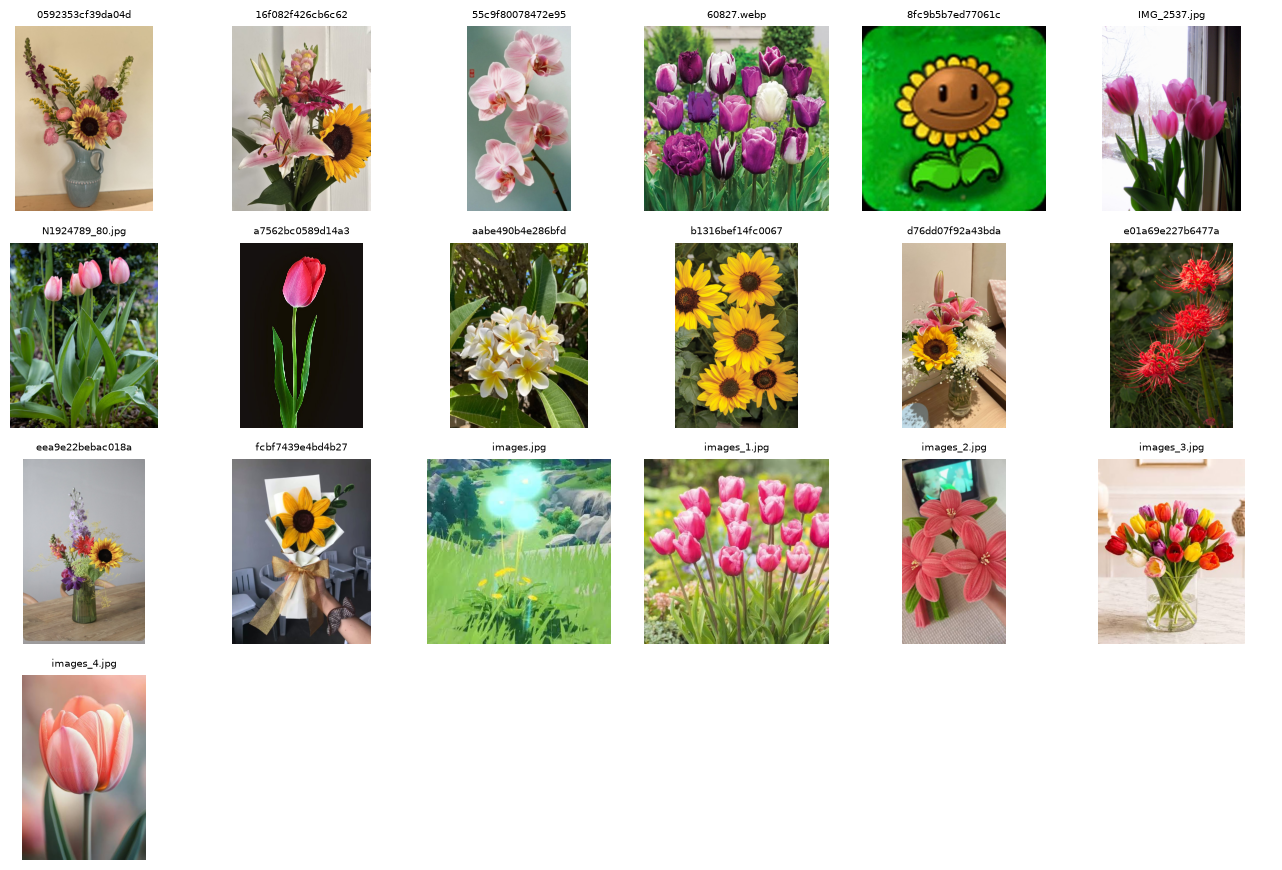

In [24]:
import io, os, glob
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
try:
    from google.colab import files
except ImportError:   # VS Code / เครื่องตัวเอง: อ่านรูปจากโฟลเดอร์แทนการอัปโหลด
    files = None

IMAGE_DIR = "."   # (VS Code) โฟลเดอร์ของรูปที่จะตรวจ
LOCAL_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".avif", ".bmp")

image_bank = []   # list ของ (ชื่อไฟล์, รูป PIL)


def clear_images():
    image_bank.clear()
    print("ล้างรายการรูปแล้ว")


def show_bank(cols=6):
    n = len(image_bank)
    if n == 0:
        print("ยังไม่มีรูป")
        return

    # คำนวณจำนวนแถวและคอลัมน์ให้ยืดหยุ่น
    actual_cols = min(n, cols)
    rows = (n + actual_cols - 1) // actual_cols if actual_cols > 0 else 1

    fig, axes = plt.subplots(rows, actual_cols, figsize=(2.2 * actual_cols, 2.2 * rows))

    # จัดการแกนแสดงผล (axes) ให้เป็น Flat list เสมอไม่ว่าจะอัปโหลดกี่รูป
    if n == 1:
        axes = [axes]
    elif hasattr(axes, 'flatten'):
        axes = axes.flatten()
    else:
        axes = [axes]

    for ax in axes:
        ax.axis("off")

    for ax, (name, im) in zip(axes, image_bank):
        ax.imshow(im)
        ax.set_title(name[:16], fontsize=7)
    plt.tight_layout()
    plt.show()


def add_images(folder=IMAGE_DIR):
    existing = {n for n, _ in image_bank}
    if files is not None:
        up = files.upload()
    else:   # รันซ้ำได้ จะเพิ่มเฉพาะไฟล์ใหม่ในโฟลเดอร์
        up = {os.path.basename(f): Path(f).read_bytes()
              for f in sorted(glob.glob(os.path.join(folder, "*")))
              if f.lower().endswith(LOCAL_EXTS) and os.path.basename(f) not in existing}
    for fname, data in up.items():
        try:
            im = Image.open(io.BytesIO(data)).convert("RGB")
        except Exception:
            print("⚠️ อ่านไฟล์ไม่ได้ ข้าม:", fname)
            continue
        name, k = fname, 2
        while name in existing:                  # ชื่อซ้ำ → ต่อท้ายเลข
            name = f"{fname.rsplit('.', 1)[0]}_{k}"
            k += 1
        existing.add(name)
        image_bank.append((name, im))
    print(f"✅ ตอนนี้มีรูปในรายการ {len(image_bank)} รูป")
    show_bank()


add_images()

## 8) กดตรวจทั้งหมด + สรุปรวม

[1/19] กำลังตรวจ 0592353cf39da04db74a1d5cbd4e23da.jpg ...


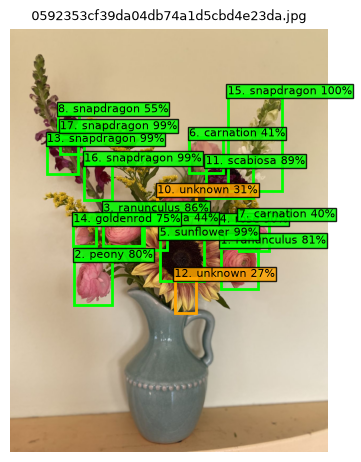

0592353cf39da04db74a1d5cbd4e23da.jpg: พบ 17 ดอก → snapdragon 5, ranunculus 2, carnation 2, unknown 2, peony 1, rose 1, sunflower 1, zinnia 1, scabiosa 1, goldenrod 1  [ตัดกล่องที่ไม่ใช่ดอกไม้ 1 กล่อง]
   1. ranunculus 81%, carnation 5%, stock 5%
   2. peony 80%, carnation 9%, ranunculus 4%
   3. ranunculus 86%, rose 5%, peony 3%
   4. rose 90%, carnation 5%, camellia 2%
   5. sunflower 99%, chrysanthemum 0%, zinnia 0%
   6. carnation 41%, rose 23%, tulip 7%
   7. carnation 40%, ranunculus 29%, rose 12%
   8. snapdragon 55%, lisianthus 17%, orchid 13%
   9. zinnia 44%, sunflower 19%, dahlia 16%
   10. carnation 31%, peony 29%, tulip 14%
   11. scabiosa 89%, dahlia 4%, zinnia 2%
   12. dahlia 27%, chrysanthemum 14%, sunflower 14%
   13. snapdragon 99%, hyacinth 0%, stock 0%
   14. goldenrod 75%, alstroemeria 5%, carnation 2%
   15. snapdragon 100%, sweet pea 0%, stock 0%
   16. snapdragon 99%, sweet pea 0%, lisianthus 0%
   17. snapdragon 99%, stock 1%, sweet pea 0%
[2/19] กำลังตรวจ 16f0

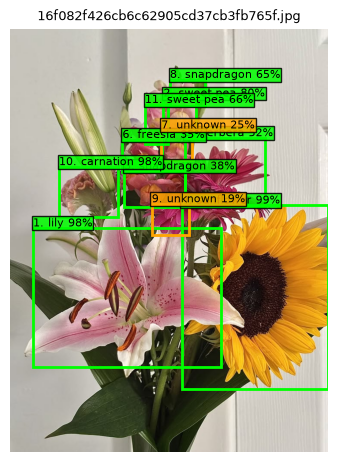

16f082f426cb6c62905cd37cb3fb765f.jpg: พบ 11 ดอก → sweet pea 2, snapdragon 2, unknown 2, lily 1, sunflower 1, gerbera 1, freesia 1, carnation 1
   1. lily 98%, alstroemeria 2%, calla lily 0%
   2. sweet pea 80%, freesia 8%, snapdragon 5%
   3. snapdragon 38%, gladiolus 22%, freesia 19%
   4. sunflower 99%, chrysanthemum 0%, gerbera 0%
   5. gerbera 52%, chrysanthemum 37%, daisy 6%
   6. freesia 35%, snapdragon 21%, sweet pea 16%
   7. calla lily 25%, freesia 23%, sweet pea 14%
   8. snapdragon 65%, freesia 28%, lisianthus 1%
   9. alstroemeria 19%, lisianthus 17%, tulip 13%
   10. carnation 98%, freesia 0%, lisianthus 0%
   11. sweet pea 66%, stock 19%, snapdragon 10%
[3/19] กำลังตรวจ 55c9f80078472e95012a5ddee2e1511c.jpg ...


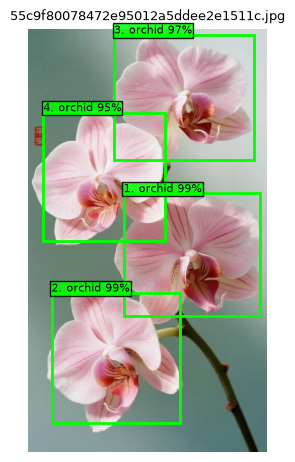

55c9f80078472e95012a5ddee2e1511c.jpg: พบ 4 ดอก → orchid 4
   1. orchid 99%, anthurium 0%, lily 0%
   2. orchid 99%, anthurium 1%, lily 0%
   3. orchid 97%, anthurium 2%, stock 0%
   4. orchid 95%, lily 2%, lotus 1%
[4/19] กำลังตรวจ 60827.webp ...


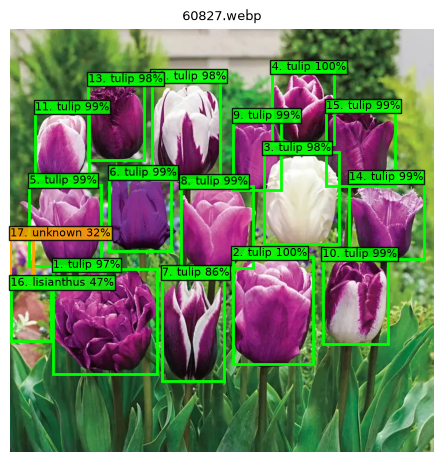

60827.webp: พบ 17 ดอก → tulip 15, lisianthus 1, unknown 1
   1. tulip 97%, peony 1%, iris 1%
   2. tulip 100%, lisianthus 0%, peony 0%
   3. tulip 98%, lisianthus 0%, sweet pea 0%
   4. tulip 100%, lisianthus 0%, magnolia 0%
   5. tulip 99%, anemone 0%, poppy 0%
   6. tulip 99%, calla lily 0%, anemone 0%
   7. tulip 86%, lisianthus 10%, calla lily 2%
   8. tulip 99%, sweet pea 0%, poppy 0%
   9. tulip 99%, lisianthus 0%, calla lily 0%
   10. tulip 99%, calla lily 0%, lisianthus 0%
   11. tulip 99%, lisianthus 0%, sweet pea 0%
   12. tulip 98%, lisianthus 1%, magnolia 1%
   13. tulip 98%, poppy 0%, peony 0%
   14. tulip 99%, lisianthus 0%, calla lily 0%
   15. tulip 99%, lisianthus 0%, sweet pea 0%
   16. lisianthus 47%, tulip 13%, stock 6%
   17. tulip 32%, lisianthus 25%, sweet pea 11%
[5/19] กำลังตรวจ 8fc9b5b7ed77061c826fc8956245a739.jpg ...


[6/19] กำลังตรวจ IMG_2537.jpg ...


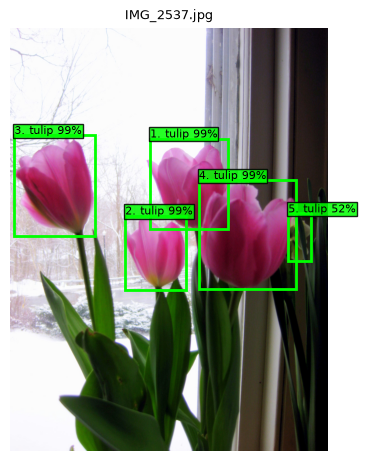

IMG_2537.jpg: พบ 5 ดอก → tulip 5  [ตัดกล่องที่ไม่ใช่ดอกไม้ 2 กล่อง]
   1. tulip 99%, magnolia 1%, peony 0%
   2. tulip 99%, magnolia 0%, peony 0%
   3. tulip 99%, magnolia 0%, poppy 0%
   4. tulip 99%, calla lily 0%, magnolia 0%
   5. tulip 52%, sweet pea 23%, daffodil 6%
[7/19] กำลังตรวจ N1924789_80.jpg ...


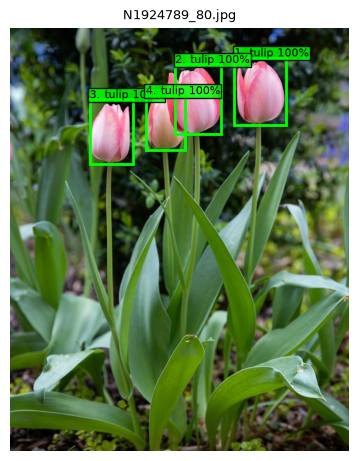

N1924789_80.jpg: พบ 4 ดอก → tulip 4  [ตัดกล่องที่ไม่ใช่ดอกไม้ 1 กล่อง]
   1. tulip 100%, lily 0%, calla lily 0%
   2. tulip 100%, magnolia 0%, lily 0%
   3. tulip 100%, calla lily 0%, lily 0%
   4. tulip 100%, calla lily 0%, lily 0%
[8/19] กำลังตรวจ a7562bc0589d14a376f81a8b768c74abe8454d62-500x750.avif ...


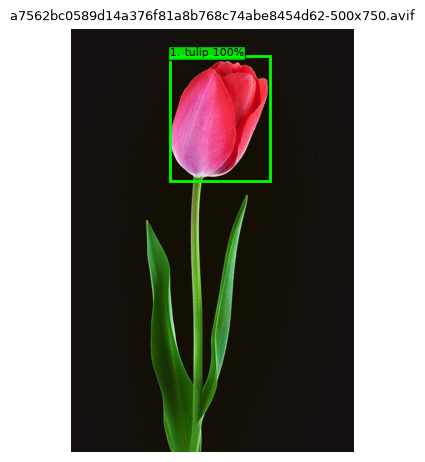

a7562bc0589d14a376f81a8b768c74abe8454d62-500x750.avif: พบ 1 ดอก → tulip 1
   1. tulip 100%, lily 0%, stock 0%
[9/19] กำลังตรวจ aabe490b4e286bfdecf0d460061101d7.jpg ...


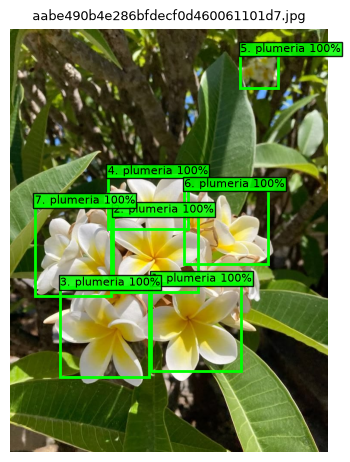

aabe490b4e286bfdecf0d460061101d7.jpg: พบ 7 ดอก → plumeria 7  [ตัดกล่องที่ไม่ใช่ดอกไม้ 1 กล่อง]
   1. plumeria 100%, gardenia 0%, magnolia 0%
   2. plumeria 100%, gardenia 0%, lisianthus 0%
   3. plumeria 100%, gardenia 0%, jasmine 0%
   4. plumeria 100%, gardenia 0%, lisianthus 0%
   5. plumeria 100%, gardenia 0%, jasmine 0%
   6. plumeria 100%, gardenia 0%, jasmine 0%
   7. plumeria 100%, gardenia 0%, lisianthus 0%
[10/19] กำลังตรวจ b1316bef14fc00672e7e0adaf461c7ee.jpg ...


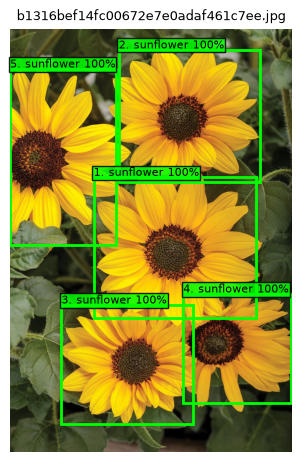

b1316bef14fc00672e7e0adaf461c7ee.jpg: พบ 5 ดอก → sunflower 5
   1. sunflower 100%, chrysanthemum 0%, zinnia 0%
   2. sunflower 100%, chrysanthemum 0%, zinnia 0%
   3. sunflower 100%, chrysanthemum 0%, zinnia 0%
   4. sunflower 100%, chrysanthemum 0%, zinnia 0%
   5. sunflower 100%, chrysanthemum 0%, zinnia 0%
[11/19] กำลังตรวจ d76dd07f92a43bda83d8db27daba87df.jpg ...


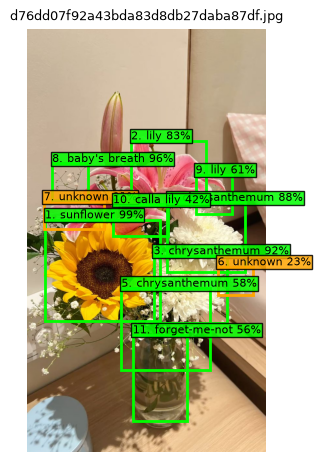

d76dd07f92a43bda83d8db27daba87df.jpg: พบ 11 ดอก → chrysanthemum 3, lily 2, unknown 2, sunflower 1, baby's breath 1, calla lily 1, forget-me-not 1  [ตัดกล่องที่ไม่ใช่ดอกไม้ 1 กล่อง]
   1. sunflower 99%, chrysanthemum 0%, gerbera 0%
   2. lily 83%, calla lily 11%, alstroemeria 2%
   3. chrysanthemum 92%, dahlia 5%, daisy 1%
   4. chrysanthemum 88%, peony 3%, daisy 3%
   5. chrysanthemum 58%, daisy 16%, baby's breath 8%
   6. baby's breath 23%, stock 16%, lisianthus 14%
   7. plumeria 21%, calla lily 13%, anthurium 12%
   8. baby's breath 96%, wax flower 1%, scabiosa 1%
   9. lily 61%, calla lily 24%, alstroemeria 5%
   10. calla lily 42%, rose 19%, plumeria 11%
   11. forget-me-not 56%, wax flower 10%, baby's breath 5%
[12/19] กำลังตรวจ e01a69e227b6477a0a0bcff775f626f6.jpg ...


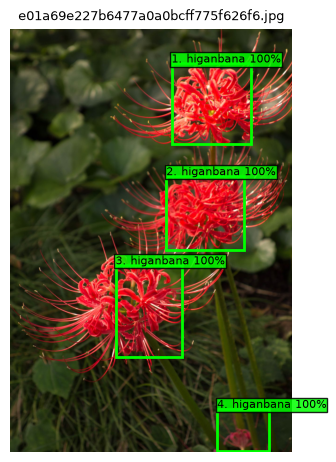

e01a69e227b6477a0a0bcff775f626f6.jpg: พบ 4 ดอก → higanbana 4
   1. higanbana 100%, lily 0%, alstroemeria 0%
   2. higanbana 100%, lily 0%, orchid 0%
   3. higanbana 100%, lily 0%, alstroemeria 0%
   4. higanbana 100%, lily 0%, orchid 0%
[13/19] กำลังตรวจ eea9e22bebac018a1adf6e6a854f2472.jpg ...


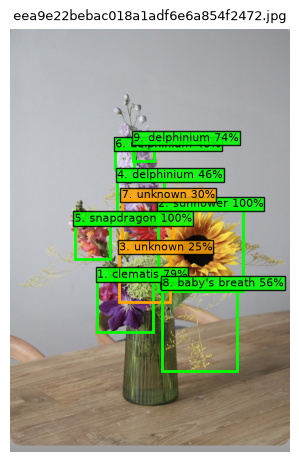

eea9e22bebac018a1adf6e6a854f2472.jpg: พบ 9 ดอก → delphinium 3, unknown 2, clematis 1, sunflower 1, snapdragon 1, baby's breath 1
   1. clematis 79%, delphinium 10%, lisianthus 8%
   2. sunflower 100%, dahlia 0%, chrysanthemum 0%
   3. lilac 25%, delphinium 15%, hydrangea 14%
   4. delphinium 46%, stock 20%, lisianthus 14%
   5. snapdragon 100%, stock 0%, lisianthus 0%
   6. delphinium 40%, clematis 21%, lisianthus 18%
   7. gerbera 30%, chrysanthemum 21%, carnation 14%
   8. baby's breath 56%, lilac 21%, clematis 4%
   9. delphinium 74%, lisianthus 7%, clematis 6%
[14/19] กำลังตรวจ fcbf7439e4bd4b27cb02049b3c951ede.png ...


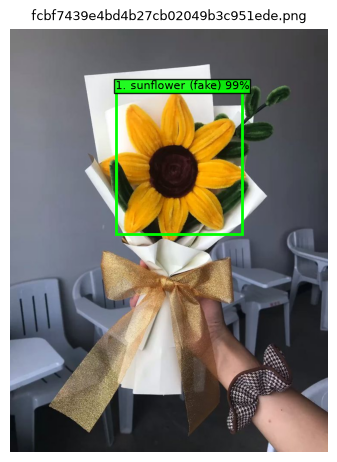

fcbf7439e4bd4b27cb02049b3c951ede.png: พบ 1 ดอก → sunflower 1  [ตัดกล่องที่ไม่ใช่ดอกไม้ 3 กล่อง]
   🌼 ดอกไม้ปลอม (82%) → ใช้ CLIP ช่วยบอกชนิด
   1. sunflower 99%, daisy 0%, gerbera 0%
[15/19] กำลังตรวจ images.jpg ...


[16/19] กำลังตรวจ images_1.jpg ...


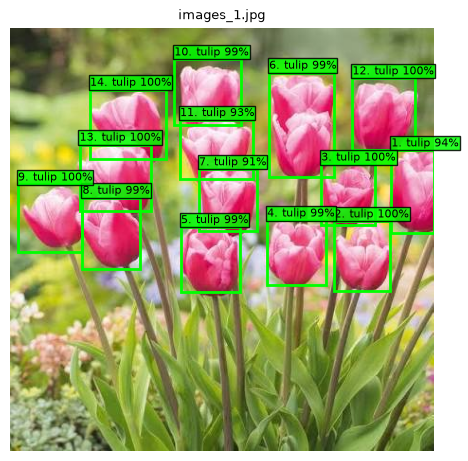

images_1.jpg: พบ 14 ดอก → tulip 14
   1. tulip 94%, carnation 1%, stock 1%
   2. tulip 100%, poppy 0%, lily 0%
   3. tulip 100%, lily 0%, carnation 0%
   4. tulip 99%, lily 0%, calla lily 0%
   5. tulip 99%, carnation 0%, stock 0%
   6. tulip 99%, carnation 0%, lily 0%
   7. tulip 91%, carnation 4%, stock 1%
   8. tulip 99%, carnation 0%, poppy 0%
   9. tulip 100%, lily 0%, poppy 0%
   10. tulip 99%, carnation 0%, stock 0%
   11. tulip 93%, stock 2%, carnation 1%
   12. tulip 100%, lily 0%, poppy 0%
   13. tulip 100%, carnation 0%, lily 0%
   14. tulip 100%, carnation 0%, poppy 0%
[17/19] กำลังตรวจ images_2.jpg ...


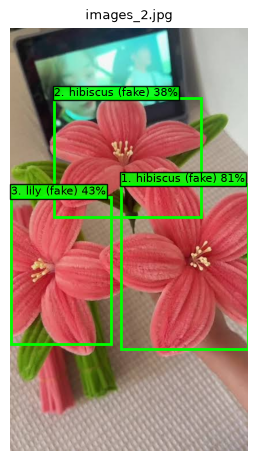

images_2.jpg: พบ 3 ดอก → hibiscus 2, lily 1
   🌼 ดอกไม้ปลอม (83%) → ใช้ CLIP ช่วยบอกชนิด
   1. hibiscus 81%, clematis 15%, lily 1%
   2. hibiscus 38%, lily 14%, anthurium 10%
   3. lily 43%, hibiscus 18%, stock 8%
[18/19] กำลังตรวจ images_3.jpg ...


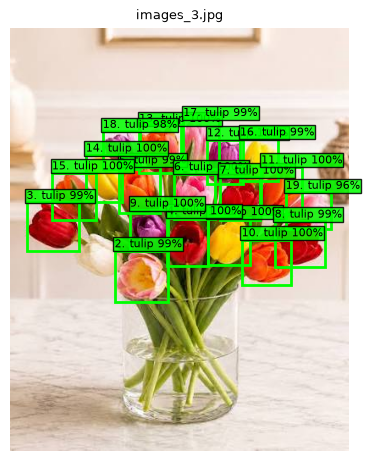

images_3.jpg: พบ 19 ดอก → tulip 19  [ตัดกล่องที่ไม่ใช่ดอกไม้ 1 กล่อง]
   1. tulip 100%, calla lily 0%, alstroemeria 0%
   2. tulip 99%, calla lily 0%, peony 0%
   3. tulip 99%, carnation 0%, stock 0%
   4. tulip 100%, calla lily 0%, stock 0%
   5. tulip 99%, stock 0%, calla lily 0%
   6. tulip 100%, calla lily 0%, stock 0%
   7. tulip 100%, stock 0%, calla lily 0%
   8. tulip 99%, stock 0%, carnation 0%
   9. tulip 100%, stock 0%, lisianthus 0%
   10. tulip 100%, calla lily 0%, stock 0%
   11. tulip 100%, stock 0%, calla lily 0%
   12. tulip 100%, stock 0%, magnolia 0%
   13. tulip 100%, stock 0%, calla lily 0%
   14. tulip 100%, calla lily 0%, carnation 0%
   15. tulip 100%, calla lily 0%, stock 0%
   16. tulip 99%, stock 0%, daffodil 0%
   17. tulip 99%, stock 0%, hyacinth 0%
   18. tulip 98%, stock 1%, carnation 0%
   19. tulip 96%, carnation 1%, rose 1%
[19/19] กำลังตรวจ images_4.jpg ...


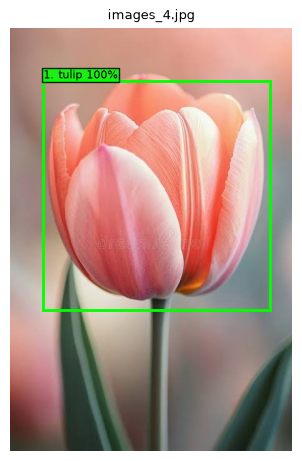

images_4.jpg: พบ 1 ดอก → tulip 1
   1. tulip 100%, lily 0%, calla lily 0%


ชนิด,จำนวนดอก,อยู่ในกี่รูป
tulip,59,7
sunflower,10,6
unknown,9,5
snapdragon,8,3
plumeria,7,1
lily,4,3
orchid,4,1
higanbana,4,1
carnation,3,2
chrysanthemum,3,1


In [25]:
from collections import Counter, defaultdict
from IPython.display import display, HTML
import matplotlib.patches as patches


def summarize(results):
    """results = list ของ (ชื่อรูป, ผล analyze_image) → สรุปรวมทุกรูป (ฟังก์ชันล้วน ไม่แตะโมเดล)"""
    total, in_images = Counter(), defaultdict(set)
    n_flower_imgs, rejected = 0, []
    for name, r in results:
        if not r["is_flower"]:
            rejected.append(name)
            continue
        n_flower_imgs += 1
        for it in r["items"]:
            total[it["label"]] += 1
            in_images[it["label"]].add(name)
    return {"total": total, "in_images": {k: len(v) for k, v in in_images.items()},
            "n_images": len(results), "n_flower_images": n_flower_imgs, "rejected": rejected,
            "n_flowers": sum(total.values())}


def draw_result(name, img, r):
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.imshow(img)
    for i, it in enumerate(r["items"], 1):
        x0, y0, x1, y1 = it["box"]
        color = "orange" if it["label"] == UNKNOWN else "lime"
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=2))
        ax.text(x0, max(y0 - 4, 8), f"{i}. {it['label']}{' (fake)' if r.get('artificial') else ''} {it['conf']:.0%}", fontsize=8, color="black",
                bbox=dict(facecolor=color, alpha=0.85, pad=1))
    ax.set_title(name, fontsize=9)
    ax.axis("off")
    plt.show()


def run_all():
    if not image_bank:
        print("ยังไม่มีรูป — รันเซลล์ที่ 7 เพื่อเพิ่มรูปก่อน")
        return None
    results = []
    for k, (name, img) in enumerate(image_bank, 1):
        print("=" * 60)
        print(f"[{k}/{len(image_bank)}] กำลังตรวจ {name} ...", flush=True)
        r = analyze_image(img)
        results.append((name, r))
        if not r["is_flower"]:
            what, pct = r["looks_like"]
            display(HTML(
                "<div style='background:#fdecea;border:2px solid #d93025;color:#b3261e;"
                "padding:10px;border-radius:8px'>"
                + (f"⚠️ <b>{name}</b>: เป็นดอกไม้การ์ตูน/ในเกม/ภาพวาด ไม่นับ กรุณาใช้รูปถ่ายดอกไม้จริงหรือดอกไม้ปลอม<br>"
                   f"<span style='font-size:12px'>โอกาสเป็นการ์ตูน/เกม {pct:.1%}</span></div>"
                   if r.get("reason") == "drawn" else
                   f"⚠️ <b>{name}</b>: ไม่พบดอกไม้ในรูปนี้ กรุณาเพิ่มรูปดอกไม้เข้ามา<br>"
                   f"<span style='font-size:12px'>โอกาสเป็นดอกไม้ {r['p_flower']:.1%} "
                   f"(ใกล้เคียง: {what} {pct:.1%})</span></div>")))
            continue
        draw_result(name, img, r)
        c = Counter(it["label"] for it in r["items"])
        txt = ", ".join(f"{k} {v}" for k, v in c.most_common())
        note = "  (detector ไม่เจอกล่อง ใช้ทั้งรูปเป็น 1 ดอก)" if r["fallback"] else ""
        extra = f"  [ตัดกล่องที่ไม่ใช่ดอกไม้ {r['dropped']} กล่อง]" if r["dropped"] else ""
        print(f"{name}: พบ {len(r['items'])} ดอก → {txt}{note}{extra}")
        if r.get("artificial"):
            print(f"   🌼 ดอกไม้ปลอม ({r['p_fake']:.0%}) → ใช้ CLIP ช่วยบอกชนิด")
        if SHOW_TOP3:
            for i, it in enumerate(r["items"], 1):
                alts = ", ".join(f"{n} {p:.0%}" for n, p in it["top3"])
                print(f"   {i}. {alts}")

    s = summarize(results)
    rows = "".join(
        f"<tr><td>{k}</td><td style='text-align:center'>{v}</td>"
        f"<td style='text-align:center'>{s['in_images'][k]}</td></tr>"
        for k, v in s["total"].most_common())
    rej = ""
    if s["rejected"]:
        rej = ("<p style='color:#b3261e'>⚠️ รูปที่ไม่ใช่ดอกไม้ (" + str(len(s["rejected"])) + " รูป): "
               + ", ".join(s["rejected"]) + " — กรุณาเพิ่มรูปดอกไม้</p>")
    display(HTML(
        "<div style='background:#e6f4ea;border:2px solid #188038;color:#0d3b1f;"
        "padding:14px;border-radius:8px;margin-top:12px'>"
        f"<h3 style='margin:0 0 8px 0'>🌸 สรุปรวม: {s['n_flowers']} ดอก จาก {s['n_flower_images']}/{s['n_images']} รูป</h3>"
        "<table style='border-collapse:collapse;min-width:320px'>"
        "<tr><th style='text-align:left'>ชนิด</th><th>จำนวนดอก</th><th>อยู่ในกี่รูป</th></tr>"
        f"{rows}</table>{rej}</div>"))
    return results


results = run_all()